In [1]:
import pandas as pd
import plotly.express as px
print(pd.__version__)

3.0.6


In [2]:
df = pd.read_csv("dvf-59.csv", low_memory=False)
df.head()
df.columns





Index(['annee', 'id_mutation', 'date_mutation', 'numero_disposition',
       'nature_mutation', 'valeur_fonciere', 'adresse_numero',
       'adresse_suffixe', 'adresse_nom_voie', 'adresse_code_voie',
       'code_postal', 'code_commune', 'nom_commune', 'code_departement',
       'ancien_code_commune', 'ancien_nom_commune', 'id_parcelle',
       'ancien_id_parcelle', 'numero_volume', 'lot1_numero',
       'lot1_surface_carrez', 'lot2_numero', 'lot2_surface_carrez',
       'lot3_numero', 'lot3_surface_carrez', 'lot4_numero',
       'lot4_surface_carrez', 'lot5_numero', 'lot5_surface_carrez',
       'nombre_lots', 'code_type_local', 'type_local', 'surface_reelle_bati',
       'nombre_pieces_principales', 'code_nature_culture', 'nature_culture',
       'code_nature_culture_speciale', 'nature_culture_speciale',
       'surface_terrain', 'longitude', 'latitude', 'logement'],
      dtype='str')

In [3]:
df.drop(['numero_disposition',
       'nature_mutation','adresse_numero',
       'adresse_suffixe','adresse_nom_voie','adresse_code_voie','code_commune','code_departement',
       'ancien_code_commune','ancien_nom_commune','id_parcelle',
        'ancien_id_parcelle','numero_volume','lot1_numero',
       'lot1_surface_carrez','lot2_numero','lot2_surface_carrez',
       'lot3_numero','lot3_surface_carrez','lot4_numero',
       'lot4_surface_carrez','lot5_numero','lot5_surface_carrez',
       'nombre_lots','code_type_local',
       'nombre_pieces_principales','code_nature_culture','nature_culture',
       'code_nature_culture_speciale','nature_culture_speciale','longitude','latitude', 'logement'], axis=1, inplace=True)

df.columns


Index(['annee', 'id_mutation', 'date_mutation', 'valeur_fonciere',
       'code_postal', 'nom_commune', 'type_local', 'surface_reelle_bati',
       'surface_terrain'],
      dtype='str')

In [4]:
df = df.dropna(axis=0)

In [5]:
df['prix au m2'] = df['valeur_fonciere'] / df['surface_reelle_bati']
df.describe()

,annee,valeur_fonciere,code_postal,surface_reelle_bati,surface_terrain,prix au m2
count,198904.000000,1.989040e+05,198904.000000,198904.000000,198904.000000,1.989040e+05
mean,2020.061080,2.781591e+06,59363.762770,135.517848,773.698875,4.596455e+04
std,1.399837,1.973348e+07,248.175456,687.183085,4831.263632,3.494389e+05
min,2018.000000,1.500000e-01,59000.000000,1.000000,1.000000,1.724138e-05
25%,2019.000000,1.181500e+05,59169.000000,65.000000,144.000000,1.310345e+03
50%,2020.000000,1.821000e+05,59279.000000,86.000000,283.000000,2.030308e+03
75%,2021.000000,2.960000e+05,59540.000000,112.000000,556.000000,3.280055e+03
max,2022.000000,7.225900e+08,59990.000000,79300.000000,445042.000000,1.980070e+07


In [6]:
biens = df[df['type_local'].isin(['Appartement', 'Maison'])]
cles = ['id_mutation','valeur_fonciere','nom_commune']
biens = biens.drop_duplicates(subset=cles, keep=False)
biens = biens[(biens['surface_reelle_bati'] >= 15) & (biens['prix au m2'].between(800, 8000))]

In [7]:
df = df[df['prix au m2'].between(100, 7000)]

In [8]:
maison = df[df['type_local'] == 'Maison']
appart = df[df['type_local'] == 'Appartement']

<Axes: ylabel='nom_commune,type_local'>

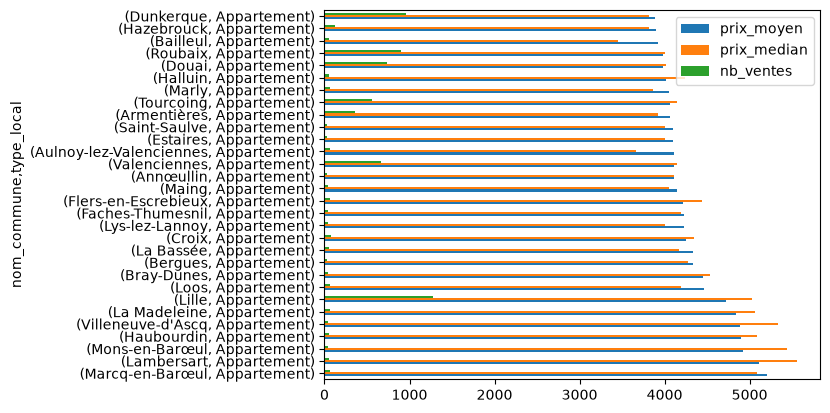

In [9]:
stats = df.groupby(['nom_commune', 'type_local'])['prix au m2'].agg(
    prix_moyen = 'mean',
    prix_median = 'median',
    nb_ventes = 'count'
)
stats = stats[stats['nb_ventes'] > 30]
stats.sort_values('prix_moyen', ascending=False).head(30).plot(kind='barh')


In [10]:
biens.to_csv('dvf_59_propre.csv', index=False)